# Phase 2 – Part A: Unsupervised Learning
## Clustering Algorithm 1: K-Means


## 1. Clustering Rationale – K-Means

**Goal:** group credit card clients into segments with similar financial behavior, **without using the default label**. The segments can then be used to explain the risk predictions and to support decisions in the executive dashboard.

**Why K-Means:**
- **Dataset size:** the training set has 24,000 clients. K-Means is fast and scales well to this size, while methods that compare every pair of points (such as hierarchical clustering) need much more memory and time.
- **Feature types:** after preprocessing, all features we use are numeric and standardized (mean 0, standard deviation 1), which is what K-Means needs because it groups points by Euclidean distance.
- **Expected cluster shapes:** K-Means assumes roughly spherical (round) clusters of similar spread. This is a simplification for financial data, so we check the cluster quality with several metrics instead of assuming it.
- **Interpretability:** every cluster is described by one center (centroid), so each segment can be explained to a manager as an "average client" of that group.

**Limitations:** the number of clusters *k* must be chosen in advance, and K-Means is sensitive to outliers and to the starting points. We handle this by testing *k* from 2 to 10 and by running each model 10 times with different starting points (`n_init=10`).

In [44]:
# imports and paths
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score

RANDOM_STATE = 42  # same as phase 1
TARGET = "default.payment.next.month"

# works if the notebook is in the repo root or inside Unsupervised_Learning/
ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent

RESULTS_DIR = ROOT / "Unsupervised_Learning" / "clustering_results"
PLOTS_DIR = RESULTS_DIR / "plots"
MODELS_DIR = RESULTS_DIR / "models"
for folder in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project root:", ROOT)

Project root: /content/SWE485-Project-Group1


In [45]:
# load the preprocessed data from phase 1
data = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")

# remove the target (clustering is unsupervised), id and split columns
# also drop the education one-hot columns (0/1 dummies dont work well with distances)
cluster_features = [c for c in data.columns
                    if c not in ["ID", TARGET, "split"] and not c.startswith("EDUCATION_")]

train_mask = data["split"] == "train"
X_all = data[cluster_features]          # all 30,000 clients
X_train_km = X_all[train_mask]          # fit only on the train split (no leakage)

print("Features used:", len(cluster_features))
print(cluster_features)
print("Training rows:", X_train_km.shape[0], "| All rows:", X_all.shape[0])

# scaling check: numeric features were standardized on train in phase 1
scale_check = X_train_km.agg(["mean", "std"]).T.round(2)
display(scale_check.head(8))

assert X_train_km.shape == (24000, 22) and X_all.shape == (30000, 22)
assert np.allclose(scale_check["mean"], 0, atol=0.01) and np.allclose(scale_check["std"], 1, atol=0.01)
print("All features are already standardized (mean 0, std 1).")

Features used: 22
['LIMIT_BAL', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'AGE', 'MONTHS_LATE', 'UTILIZATION', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
Training rows: 24000 | All rows: 30000


,mean,std
LIMIT_BAL,-0.0,1.0
PAY_AMT1,-0.0,1.0
PAY_AMT2,0.0,1.0
PAY_AMT3,-0.0,1.0
PAY_AMT4,0.0,1.0
PAY_AMT5,-0.0,1.0
PAY_AMT6,0.0,1.0
BILL_AMT1,0.0,1.0


All features are already standardized (mean 0, std 1).


## 2. Data Preparation

- **Source:** `Dataset/preprocessed_data.csv`, the output of the preprocessing pipeline in Phase 1.
- **Target removal:** the column `default.payment.next.month` was removed, because clustering is unsupervised and must not see the class label. `ID` and `split` were also removed because they are not client characteristics.
- **EDUCATION columns removed:** the 7 one-hot EDUCATION columns only take values 0 or 1. K-Means measures distance, so these dummy columns would create artificial gaps between clients with different education levels. EDUCATION also had almost no predictive importance in Phase 1 (Section 7 of the supervised notebook). This leaves **22 features**: credit limit, bill amounts, payment amounts, repayment status (PAY_0 to PAY_6), age, and the engineered features MONTHS_LATE and UTILIZATION.
- **Feature scaling:** K-Means is distance-based, so features must be on the same scale; otherwise large monetary values would dominate. The check above confirms that all 22 features were already **standardized** (mean 0, standard deviation 1) by the Phase 1 pipeline, so no extra scaling is needed.
- **Train only:** the model is fitted on the **24,000 training clients** only, using the same split as Phase 1. The 6,000 test clients are then assigned to the nearest cluster. This avoids data leakage if the cluster labels are later used together with the supervised model.

In [46]:
# try k from 2 to 10 and record the 3 metrics
rng = np.random.RandomState(RANDOM_STATE)
sil_idx = rng.choice(len(X_train_km), 5000, replace=False)  # silhouette is slow so use a sample

rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_train_km)
    rows.append({
        "k": k,
        "WCSS": km.inertia_,
        "Silhouette": silhouette_score(X_train_km.iloc[sil_idx], labels[sil_idx]),
        "Davies-Bouldin": davies_bouldin_score(X_train_km, labels),
        "Smallest cluster": np.bincount(labels).min(),
    })

k_search = pd.DataFrame(rows)
k_search.to_csv(RESULTS_DIR / "kmeans_k_selection.csv", index=False)
k_search.round(3)

,k,WCSS,Silhouette,Davies-Bouldin,Smallest cluster
0,2,379462.804,0.331,1.396,6339
1,3,317424.705,0.292,1.407,3596
2,4,281767.309,0.237,1.601,3176
3,5,264001.672,0.238,1.676,2348
4,6,250308.956,0.150,1.821,2136
5,7,242045.957,0.148,1.968,1704
6,8,233114.467,0.148,2.016,1683
7,9,227107.287,0.126,1.959,1668
8,10,221135.644,0.124,1.928,1174


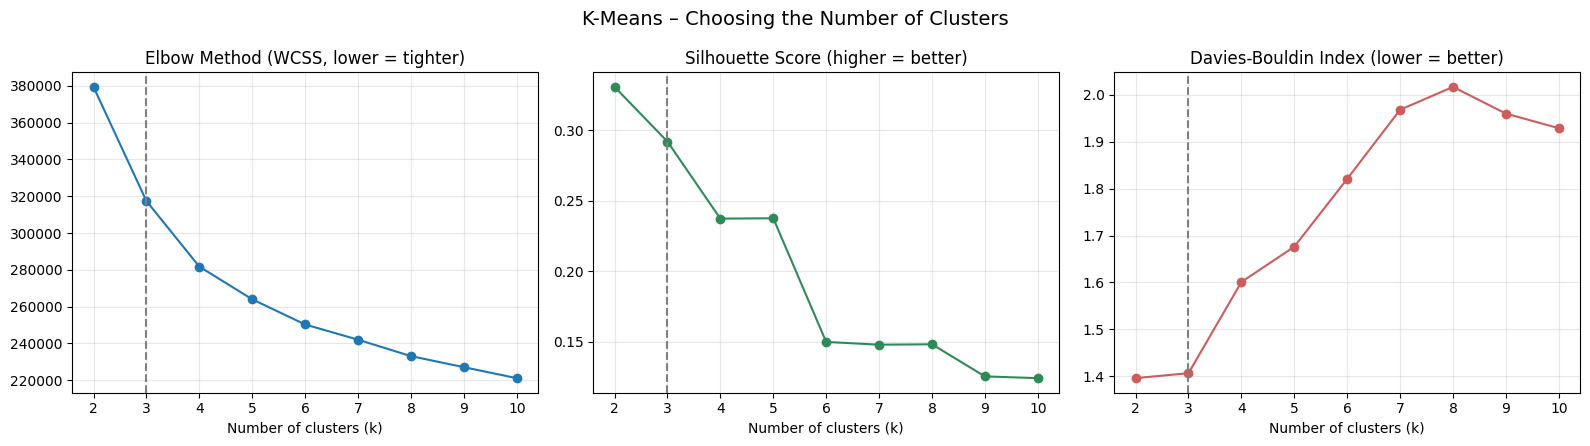

In [47]:
# plot the 3 metrics vs k
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].plot(k_search["k"], k_search["WCSS"], marker="o")
axes[0].set_title("Elbow Method (WCSS, lower = tighter)")
axes[1].plot(k_search["k"], k_search["Silhouette"], marker="o", color="seagreen")
axes[1].set_title("Silhouette Score (higher = better)")
axes[2].plot(k_search["k"], k_search["Davies-Bouldin"], marker="o", color="indianred")
axes[2].set_title("Davies-Bouldin Index (lower = better)")

for ax in axes:
    ax.set_xlabel("Number of clusters (k)")
    ax.axvline(3, linestyle="--", color="gray")   # chosen k
    ax.grid(alpha=0.3)

plt.suptitle("K-Means – Choosing the Number of Clusters", fontsize=14)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Determining the Optimal Number of Clusters

We trained K-Means for every *k* from 2 to 10 on the training set and compared three metrics:

- **WCSS (Within-Cluster Sum of Squares):** how far points are from their cluster center. It always decreases as *k* grows, so we look for the **elbow**, where adding clusters stops giving a big improvement.
- **Silhouette Score (−1 to 1):** how well each client fits its own cluster compared with the nearest other cluster. Higher is better. It was computed on a random sample of 5,000 training clients, because it compares every pair of points and would be very slow on 24,000 rows.
- **Davies-Bouldin Index:** the average similarity between each cluster and its most similar one. Lower is better.

**Results:**
- The **elbow** is at k = 3: WCSS drops from 379,463 (k=2) to 317,425 (k=3) and 281,767 (k=4), and the decrease becomes much smaller after that.
- **Silhouette** is highest at k=2 (0.331) and k=3 (0.292), then drops sharply to 0.237 at k=4.
- **Davies-Bouldin** is lowest at k=2 (1.396) and k=3 (1.407), and increases after that.

**Chosen k = 3.** k=2 and k=3 have almost the same quality (difference in Silhouette of only 0.039), but k=3 sits at the elbow and gives one more segment, which is more useful for decision-makers. Section 6 shows that the extra cluster separates a clear high-risk group that k=2 does not capture.

In [48]:
# final model with k = 3
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_train_km)

# assign every client (train + test) to the nearest center
data["kmeans_cluster"] = kmeans.predict(X_all)
train_labels = data.loc[train_mask, "kmeans_cluster"].values

final_metrics = {
    "k": K,
    "WCSS": kmeans.inertia_,
    "Silhouette (5,000 sample)": silhouette_score(X_train_km.iloc[sil_idx], train_labels[sil_idx]),
    "Davies-Bouldin": davies_bouldin_score(X_train_km, train_labels),
}
print({k: round(float(v), 3) for k, v in final_metrics.items()})

sizes = (data.groupby(["kmeans_cluster", "split"]).size().unstack()
         [["train", "test"]])
sizes["% of train"] = (sizes["train"] / sizes["train"].sum() * 100).round(1)
sizes

{'k': 3.0, 'WCSS': 317424.705, 'Silhouette (5,000 sample)': 0.292, 'Davies-Bouldin': 1.407}


split,train,test,% of train
kmeans_cluster,,,
0,15009,3779,62.5
1,5395,1330,22.5
2,3596,891,15.0


## 4. Final K-Means Model (k = 3)

The final model was trained on the 24,000 training clients and then used to assign all 30,000 clients to a cluster.

**Quality:** Silhouette = 0.292 and Davies-Bouldin = 1.407. A Silhouette around 0.3 means the clusters are reasonably separated but overlap at their borders, which is expected for credit card clients, whose behavior changes gradually rather than falling into perfectly separate groups.

**Cluster sizes:** the clusters contain 62.5%, 22.5% and 15.0% of the training clients. No cluster is tiny, so every segment is large enough to be meaningful for the bank. The test clients are distributed in similar proportions, which shows that the clusters generalize to unseen clients.

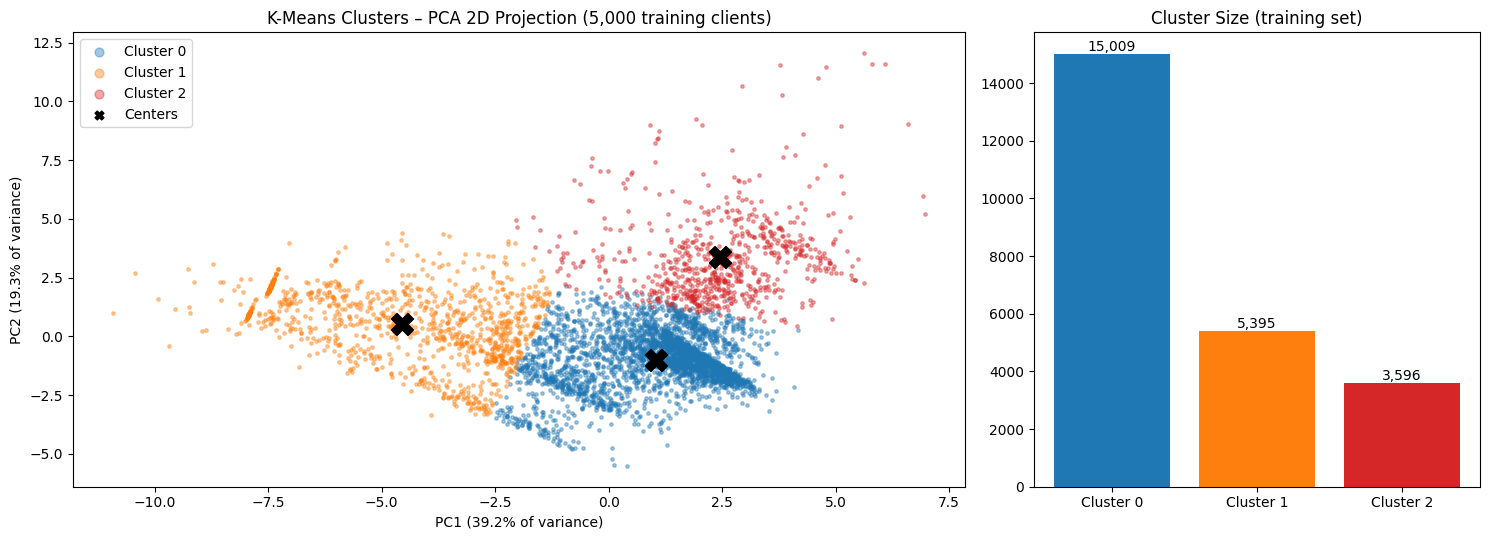

PC1 + PC2 explain 58.5% of the variance


In [49]:
# 2d pca projection to see the clusters
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_train_km)
points = pca.transform(X_train_km.iloc[sil_idx])        # same 5,000 sample
centers = pca.transform(pd.DataFrame(kmeans.cluster_centers_, columns=cluster_features))

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [2, 1]})

colors = ["tab:blue", "tab:orange", "tab:red"]
for c in range(K):
    m = train_labels[sil_idx] == c
    axes[0].scatter(points[m, 0], points[m, 1], s=6, alpha=0.4, color=colors[c], label=f"Cluster {c}")
axes[0].scatter(centers[:, 0], centers[:, 1], s=250, marker="X", color="black", label="Centers")
axes[0].set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% of variance)")
axes[0].set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% of variance)")
axes[0].set_title("K-Means Clusters – PCA 2D Projection (5,000 training clients)")
leg = axes[0].legend()
for h in leg.legend_handles:
    h.set_sizes([40])   # keep legend dots small

counts = np.bincount(train_labels)
axes[1].bar([f"Cluster {c}" for c in range(K)], counts, color=colors)
for i, v in enumerate(counts):
    axes[1].text(i, v, f"{v:,}", ha="center", va="bottom")
axes[1].set_title("Cluster Size (training set)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_pca_and_sizes.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"PC1 + PC2 explain {pca.explained_variance_ratio_[:2].sum()*100:.1f}% of the variance")

**Interpretation:**

- **PCA projection (left):** the 22 features were reduced to 2 dimensions only to draw the clusters. These two components explain 58.5% of the variance, so the picture is a simplified view and some overlap is expected. Still, the three clusters occupy different regions, and the centers (black X) are clearly apart.
- **Cluster sizes (right):** Cluster 0 is the largest group (15,009 clients), Cluster 1 has 5,395 clients, and Cluster 2 has 3,596 clients.

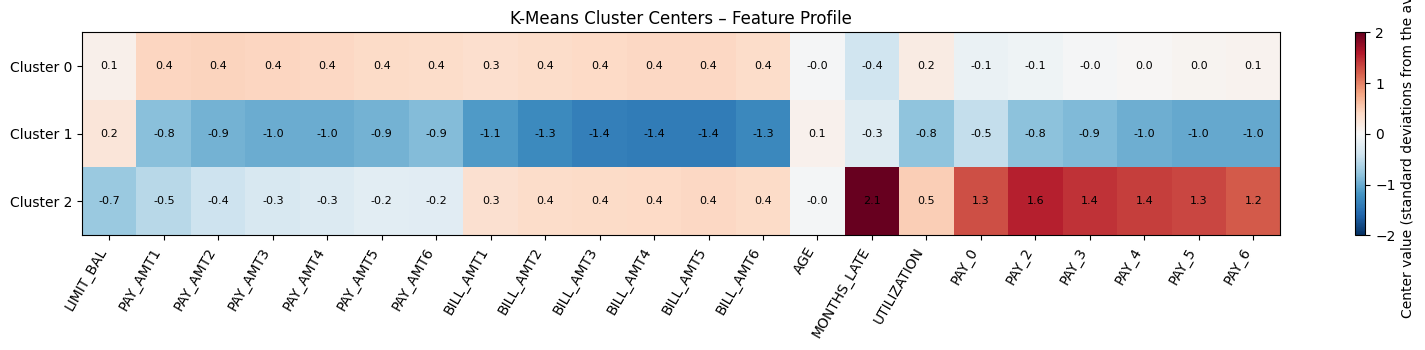

In [50]:
# feature profile per cluster = center values (in std units)
center_df = pd.DataFrame(kmeans.cluster_centers_, columns=cluster_features,
                         index=[f"Cluster {c}" for c in range(K)])
center_df.T.round(2).to_csv(RESULTS_DIR / "kmeans_cluster_centers.csv")

fig, ax = plt.subplots(figsize=(16, 3.6))
im = ax.imshow(center_df.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(len(cluster_features)))
ax.set_xticklabels(cluster_features, rotation=60, ha="right")
ax.set_yticks(range(K))
ax.set_yticklabels(center_df.index)
for i in range(K):
    for j in range(len(cluster_features)):
        ax.text(j, i, f"{center_df.values[i, j]:.1f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, label="Center value (standard deviations from the average)")
ax.set_title("K-Means Cluster Centers – Feature Profile")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "kmeans_cluster_centers.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Feature Profile per Cluster

The heatmap shows each cluster's center. Because the features are standardized, 0 means "average client", red means above average and blue means below average.

- **Cluster 0 – Active, on-time clients:** above-average bill amounts (+0.3 to +0.4) and payment amounts (about +0.4), with fewer late months than average (MONTHS_LATE −0.4) and repayment status close to normal (PAY_0 to PAY_6 between −0.14 and +0.07). These clients use their cards and pay regularly.
- **Cluster 1 – Low-activity clients:** clearly below-average bill amounts (−1.1 to −1.4), payment amounts (−0.8 to −1.0) and utilization (−0.8), with repayment status well below average (PAY_2 to PAY_6 between −0.8 and −1.0, and PAY_0 −0.5, meaning no use or paid in full). These clients barely use their cards.
- **Cluster 2 – Late-paying, high-risk clients:** very high MONTHS_LATE (+2.1) and repayment status codes (PAY_0 to PAY_6 between +1.2 and +1.6), a lower credit limit (−0.7), above-average utilization (+0.5), and below-average payments (−0.2 to −0.5) despite above-average bills. These clients carry debt but repeatedly pay late.

The features that separate the clusters the most are the **repayment status features (PAY_0 to PAY_6, MONTHS_LATE)** and the **bill amounts**. The repayment status features also match the most important features of the Random Forest model in Phase 1 (PAY_0 and MONTHS_LATE).

In [51]:
# quick check: default rate per cluster (label used only after clustering, never in training)
check = {}
for k in [2, 3]:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_train_km)
    rates = (pd.Series(data.loc[train_mask, TARGET].values)
             .groupby(km_k.labels_).mean() * 100)
    check[f"k = {k}"] = rates.round(1)

default_check = pd.DataFrame(check)
default_check.index = [f"Cluster {c}" for c in default_check.index]
default_check.index.name = "Default rate (%) in train"
default_check = default_check.fillna("-")   # k=2 has no cluster 2
default_check

,k = 2,k = 3
Default rate (%) in train,,
Cluster 0,22.7,13.8
Cluster 1,20.6,21.5
Cluster 2,-,57.6


## 6. Validation of the Chosen k with the Default Label

The default label was **not** used to build the clusters. We only use it here, after clustering, to check whether the segments are meaningful for the bank (overall default rate in the training set: 22.1%).

- **k = 2:** the two clusters have similar default rates (22.7% and 20.6%). They mainly separate active card users from inactive ones, which does not help the bank distinguish risk.
- **k = 3:** Cluster 2 has a default rate of 57.6%, about 2.6 times the overall rate, while Cluster 0 has only 13.8%. The third cluster isolates a **high-risk segment** that k=2 mixes with the other clients.

This confirms the choice of **k = 3**: it has almost the same Silhouette and Davies-Bouldin scores as k=2, but its segments are much more useful for decision-making.

In [52]:
# save everything for member 2, member 3 and the dashboard
data[["ID", "split", "kmeans_cluster"]].to_csv(RESULTS_DIR / "kmeans_labels.csv", index=False)

pd.DataFrame([final_metrics]).to_csv(RESULTS_DIR / "kmeans_final_metrics.csv", index=False)

joblib.dump(kmeans, MODELS_DIR / "kmeans_model.joblib")
with open(RESULTS_DIR / "kmeans_features.json", "w") as f:
    json.dump(cluster_features, f, indent=2)   # needed to use the model on new clients

print("Results:", sorted(p.name for p in RESULTS_DIR.glob("kmeans_*")))
print("Plots:  ", sorted(p.name for p in PLOTS_DIR.glob("kmeans_*")))
print("Model:  ", sorted(p.name for p in MODELS_DIR.glob("kmeans_*")))

Results: ['kmeans_cluster_centers.csv', 'kmeans_features.json', 'kmeans_final_metrics.csv', 'kmeans_k_selection.csv', 'kmeans_labels.csv']
Plots:   ['kmeans_cluster_centers.png', 'kmeans_k_selection.png', 'kmeans_pca_and_sizes.png']
Model:   ['kmeans_model.joblib']


## 7. K-Means Summary

| Item | Value |
|---|---|
| Features used | 22 standardized features (target, ID, split and EDUCATION removed) |
| Fitted on | 24,000 training clients (all 30,000 clients assigned) |
| Chosen k | 3 (elbow + Silhouette + Davies-Bouldin + business meaning) |
| Silhouette | 0.292 |
| Davies-Bouldin | 1.407 |
| Cluster sizes (train) | 15,009 / 5,395 / 3,596 |

**Outputs for the next steps:**
- `clustering_results/kmeans_labels.csv`: the K-Means cluster of every client (`ID`, `split`, `kmeans_cluster`), used for the comparison with the second algorithm and for the cluster profiles.
- `clustering_results/kmeans_k_selection.csv`, `kmeans_final_metrics.csv`, `kmeans_cluster_centers.csv`: all evaluation metrics as CSV files.
- `clustering_results/plots/`: all K-Means figures as PNG files.
- `clustering_results/models/kmeans_model.joblib` + `clustering_results/kmeans_features.json`: the trained model and its feature list, so the dashboard can assign a new client to a segment.

## Clustering Algorithm 2: Gaussian Mixture

The Gaussian Mixture Model uses the same 22 standardized Phase 1 features and original train/test split as Member 1. The default target, client ID, split and education dummies are excluded from the model. The EM implementation tests 2–6 components, diagonal and spherical covariance, and two initializations per configuration. The highest training-sample Silhouette selects the final converged model with all components represented.

The model is fitted on 24,000 training rows and assigns labels to all 30,000 clients. The same 5,000 training rows are used for both Silhouette scores and the PCA plots. Davies–Bouldin uses all training rows.

In [53]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageDraw

root = ROOT / "Unsupervised_Learning"
results = root / "clustering_results"
data = pd.read_csv(root.parent / "Dataset/preprocessed_data.csv")
features = json.loads((results / "kmeans_features.json").read_text())
expected = [c for c in data if c not in {"ID", "split", "default.payment.next.month"}
            and not c.startswith("EDUCATION_")]
assert features == expected
train = data.split.eq("train").to_numpy()
values = data[features].to_numpy()
x = values[train]
assert x.shape == (24000, 22) and values.shape == (30000, 22)
assert np.isfinite(values).all() and np.allclose(x.mean(0), 0, atol=.01)
assert np.allclose(x.std(0), 1, atol=.01)
sample = np.random.RandomState(42).choice(len(x), 5000, replace=False)

def distance(a, b):
    squared = (a**2).sum(1)[:, None] + (b**2).sum(1) - 2 * (a @ b.T)
    return np.sqrt(np.maximum(squared, 0))

pairwise = distance(x[sample], x[sample])
np.fill_diagonal(pairwise, 0)

def silhouette(labels):
    _, codes = np.unique(labels[sample], return_inverse=True)
    groups = np.eye(codes.max()+1)[codes]
    counts = groups.sum(0)
    if len(counts) < 2:
        return np.nan
    totals = pairwise @ groups
    rows = np.arange(len(codes))
    within = totals[rows, codes] / np.maximum(counts[codes]-1, 1)
    averages = totals / counts
    averages[rows, codes] = np.inf
    nearest = averages.min(1)
    denom = np.maximum(within, nearest)
    scores = np.divide(nearest-within, denom, out=np.zeros_like(within), where=denom>0)
    return np.where(counts[codes]==1, 0, scores).mean()

def davies_bouldin(labels):
    groups = [x[labels==c] for c in np.unique(labels)]
    centers = np.array([g.mean(0) for g in groups])
    spread = np.array([np.linalg.norm(g-c, axis=1).mean() for g,c in zip(groups,centers)])
    separation = distance(centers, centers)
    np.fill_diagonal(separation, np.inf)
    return ((spread[:,None]+spread)/separation).max(1).mean()

saved = pd.read_csv(results / "kmeans_labels.csv").set_index(["ID","split"])
clients = pd.MultiIndex.from_frame(data[["ID","split"]])
assert saved.index.is_unique and clients.is_unique and len(saved)==len(clients)
baseline = saved.reindex(clients).kmeans_cluster
assert baseline.notna().all()
km = baseline.to_numpy()[train]
reference = pd.read_csv(results / "kmeans_final_metrics.csv").iloc[0]
assert int(reference["k"]) == len(np.unique(km))
assert np.isclose(silhouette(km), reference["Silhouette (5,000 sample)"])
assert np.isclose(davies_bouldin(km), reference["Davies-Bouldin"])

def posterior(rows, weights, means, variances):
    logs = np.column_stack([
        np.log(w)-.5*(np.log(2*np.pi*v).sum()+((rows-m)**2/v).sum(1))
        for w,m,v in zip(weights,means,variances)
    ])
    peak = logs.max(1, keepdims=True)
    shifted = np.exp(logs-peak)
    total = shifted.sum(1, keepdims=True)
    return shifted/total, (peak+np.log(total)).sum()

def fit(k, covariance, seed):
    means = x[np.random.default_rng(seed).choice(len(x),k,replace=False)]
    weights = np.full(k,1/k)
    variances = np.tile(x.var(0),(k,1))
    previous = -np.inf
    squared = x**2
    for step in range(1,201):
        model = weights,means,variances
        prob, likelihood = posterior(x,*model)
        if abs(likelihood-previous)/len(x)<1e-4:
            return model, likelihood, step, True
        mass = prob.sum(0)
        if (mass<1e-12).any():
            break
        previous = likelihood
        weights = mass/len(x)
        means = prob.T @ x / mass[:,None]
        variances = np.maximum(prob.T @ squared / mass[:,None] - means**2,0)
        if covariance=="spherical":
            variances = np.broadcast_to(variances.mean(1,keepdims=True),means.shape)
        variances = np.maximum(variances, .001)
    return model, likelihood, step, False

rows, models = [], []
for k in range(2,7):
    for covariance in ("diagonal","spherical"):
        fits = [fit(k,covariance,seed) for seed in (42,43)]
        converged = [f for f in fits if f[3]]
        model, likelihood, steps, success = max(converged or fits, key=lambda f:f[1])
        labels = posterior(x,*model)[0].argmax(1)
        rows.append(dict(components=k,covariance=covariance,converged=success,
                         iterations=steps,smallest_cluster=np.bincount(labels,minlength=k).min(),
                         silhouette=silhouette(labels),log_likelihood=likelihood))
        models.append(model)
search = pd.DataFrame(rows)
eligible = search[search.converged & search.smallest_cluster.gt(0) & search.silhouette.notna()]
best = eligible.sort_values("silhouette",ascending=False,kind="stable").iloc[0]
model = models[best.name]
probabilities = posterior(values,*model)[0]
gmm_all = probabilities.argmax(1)
gmm = gmm_all[train]
comparison = pd.DataFrame([
    dict(algorithm=name,clusters=len(np.unique(labels)),
         silhouette=silhouette(labels),davies_bouldin=davies_bouldin(labels))
    for name,labels in [("K-Means",km),("Gaussian Mixture",gmm)]
])
assignments = data[["ID","split"]].assign(gmm_cluster=gmm_all,gmm_membership=probabilities.max(1))
sizes = assignments.groupby(["gmm_cluster","split"]).size().unstack(fill_value=0)
overlap = pd.crosstab(km,gmm,rownames=["kmeans_cluster"],colnames=["gmm_cluster"])
search.assign(selected=search.index==best.name).to_csv(results/"gmm_parameter_search.csv",index=False)
comparison.to_csv(results/"gmm_kmeans_comparison.csv",index=False)
assignments.to_csv(results/"gmm_labels.csv",index=False)
sizes.to_csv(results/"gmm_cluster_sizes.csv")
overlap.to_csv(results/"gmm_kmeans_train_overlap.csv")
models_dir = results/"models"
models_dir.mkdir(exist_ok=True)
np.savez_compressed(models_dir/"gmm_model.npz",weights=model[0],means=model[1],
                    variances=model[2],features=np.array(features))

# Fit common PCA axes on training rows for display only.
_, singular, axes = np.linalg.svd(x-x.mean(0),full_matrices=False)
projected = (x[sample]-x.mean(0)) @ axes[:2].T
variance = singular[:2]**2 / (singular**2).sum()
coords = (projected-projected.min(0)) / np.ptp(projected,axis=0)
colors = ["#2455A4","#B94322","#138567","#8647B1","#B47813","#287984"]
image = Image.new("RGB",(1200,620),"white")
draw = ImageDraw.Draw(image)
draw.text((40,22),"Cluster assignments on the same 5,000 training clients",fill="#111827",font_size=26)
for offset,name,labels in [(45,"K-Means",km),(635,"Gaussian Mixture",gmm)]:
    draw.text((offset,72),name,fill="#111827",font_size=22)
    draw.rectangle((offset,110,offset+520,520),outline="#68768A")
    for (a,b),label in zip(coords,labels[sample]):
        px,py = offset+5+a*510,515-b*400
        draw.ellipse((px-2,py-2,px+2,py+2),fill=colors[label])
    draw.text((offset,535),f"Horizontal PC1 ({variance[0]:.1%}) | Vertical PC2 ({variance[1]:.1%})",
              fill="#29344A",font_size=17)
    for i,label in enumerate(np.unique(labels)):
        left = offset+i*78
        draw.rectangle((left,576,left+12,588),fill=colors[label])
        draw.text((left+17,572),str(label),fill="#111827",font_size=17)
plots = results/"plots"
plots.mkdir(exist_ok=True)
image.save(plots/"gmm_kmeans_pca.png")
print(best.to_string(),comparison.to_string(index=False),sizes.to_string(),overlap.to_string(),sep="\n\n")


components                      3
covariance              spherical
converged                    True
iterations                     17
smallest_cluster             5707
silhouette                0.19561
log_likelihood     -593865.373247

       algorithm  clusters  silhouette  davies_bouldin
         K-Means         3    0.291944        1.407051
Gaussian Mixture         3    0.195610        1.674765

split        test  train
gmm_cluster             
0            2464   9860
1            2080   8433
2            1456   5707

gmm_cluster        0     1     2
kmeans_cluster                  
0               9860  3005  2144
1                  0  5395     0
2                  0    33  3563


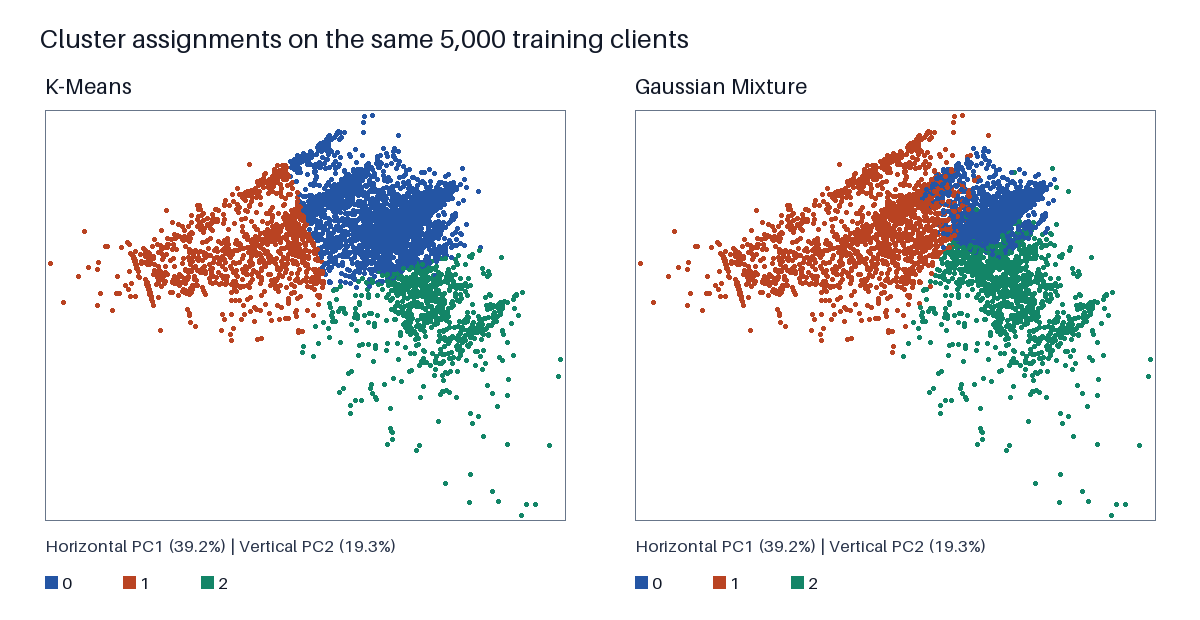

In [54]:
# show the GMM vs K-Means PCA plot
from IPython.display import Image, display
display(Image(filename=str(plots / "gmm_kmeans_pca.png")))

## Initial comparison

| Model | Clusters | Silhouette ↑ | Davies–Bouldin ↓ |
|---|---:|---:|---:|
| K-Means | 3 | 0.2919 | 1.4071 |
| Gaussian Mixture (spherical) | 3 | 0.1956 | 1.6748 |

K-Means performed better on both internal metrics. The GMM training cluster sizes were 9,860, 8,433 and 5,707. K-Means cluster 1 mapped entirely to GMM cluster 1 and 3,563 of the 3,596 clients in K-Means cluster 2 went to GMM cluster 2. K-Means cluster 0 split across all three GMM groups. The PCA projection displays the same clients and axes for both models. These training-set results describe cluster geometry and agreement. They do not measure default prediction.

The code exports tuning results, assignments, sizes, a cross-tabulation, comparison metrics, a trained model and the PCA figure to `clustering_results/`.

## Clustering Evaluation & Analysis

This part evaluates the two clustering algorithms above (K-Means and Gaussian Mixture Model).It uses their saved cluster labels to:

1. **Calculate clustering evaluation metrics** on the full data: Silhouette, Davies-Bouldin, WCSS, Calinski-Harabasz, and BCubed Precision/Recall (external validation with the default label).
2. **Compare both algorithms** and select the final one.
3. **Analyze and interpret the clusters**: feature importance per cluster and profiles in real units.
4. **Create cluster profiles** (name, risk level, description, recommended action).
5. **Prepare the clustering results for system integration** (dashboard + Generative AI prompts).

In [55]:
# imports and paths (evaluation & analysis)
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score, recall_score, precision_score,
                             roc_auc_score)
from sklearn.tree import DecisionTreeClassifier, export_text

RANDOM_STATE = 42  # same as phase 1 and the sections above
TARGET = "default.payment.next.month"

# works if the notebook is in the repo root or inside Unsupervised_Learning/
ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
UL = ROOT / "Unsupervised_Learning"
RESULTS_DIR = UL / "clustering_results"
PLOTS_DIR = RESULTS_DIR / "plots"     # same folders as the sections above
MODELS_DIR = RESULTS_DIR / "models"
for folder in [RESULTS_DIR, PLOTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

Project root: /content/SWE485-Project-Group1


## Loading the Clustering Results

- `preprocessed_data.csv`: the 22 standardized features used by both algorithms (the target `default.payment.next.month` is **not** one of them).
- `kmeans_labels.csv` and `gmm_labels.csv`: the cluster of every client (train and test) from the K-Means and GMM sections above.
- `raw_kaggle_data.csv`: the original values (NT dollars, months, years). It is only used to describe the clusters in units that a manager can understand, never to build the clusters.

In [56]:
# preprocessed data (same 22 features as K-Means and GMM)
data = pd.read_csv(ROOT / "Dataset" / "preprocessed_data.csv")
features = json.loads((RESULTS_DIR / "kmeans_features.json").read_text())

# cluster labels saved by the K-Means and GMM sections above
km_labels = pd.read_csv(RESULTS_DIR / "kmeans_labels.csv")
gmm_labels = pd.read_csv(RESULTS_DIR / "gmm_labels.csv")

df = (data.merge(km_labels, on=["ID", "split"], validate="one_to_one")
          .merge(gmm_labels, on=["ID", "split"], validate="one_to_one"))

# raw data (original units: NT dollars, months, years) -> only used to describe the clusters
raw = pd.read_csv(ROOT / "Dataset" / "raw_kaggle_data.csv")

train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)

assert len(df) == 30000 and len(train) == 24000 and len(test) == 6000
assert len(features) == 22 and TARGET not in features   # target is NOT a clustering feature
print("Clients:", len(df), "| train:", len(train), "| test:", len(test))
print("Clustering features:", len(features))
print("K-Means clusters:", sorted(df.kmeans_cluster.unique()), "| GMM clusters:", sorted(df.gmm_cluster.unique()))

Clients: 30000 | train: 24000 | test: 6000
Clustering features: 22
K-Means clusters: [np.int64(0), np.int64(1), np.int64(2)] | GMM clusters: [np.int64(0), np.int64(1), np.int64(2)]


## Internal Evaluation Metrics

Internal metrics judge the clusters using only the features (no label):

| Metric | Meaning | Better |
|---|---|---|
| **Silhouette** (−1 to 1) | How close each client is to its own cluster compared with the nearest other cluster | Higher |
| **Davies-Bouldin Index** | Average similarity between each cluster and its most similar cluster | Lower |
| **Calinski-Harabasz** | Ratio of between-cluster spread to within-cluster spread | Higher |
| **WCSS** | Total squared distance of clients to their cluster mean (compactness) | Lower |

In the sections above, the Silhouette was computed on a 5,000-client sample to save time. Here it is computed on **all 24,000 training clients** and also on the **6,000 test clients**, to check that the clusters hold on unseen data. Both algorithms use 3 clusters, so WCSS can be compared fairly.

In [57]:
def wcss(X, labels):
    """within-cluster sum of squares: squared distance of every point to its cluster mean"""
    return sum(((X[labels == c] - X[labels == c].mean(axis=0)) ** 2).sum() for c in np.unique(labels))

def internal_metrics(X, labels):
    return {
        "Silhouette": silhouette_score(X, labels),          # full data, no sampling
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
        "WCSS": wcss(X, labels),
    }

algorithms = {"K-Means": "kmeans_cluster", "GMM": "gmm_cluster"}
rows = []
for split_name, part in [("train", train), ("test", test)]:
    X = part[features].to_numpy()
    for alg, col in algorithms.items():
        rows.append({"Algorithm": alg, "Split": split_name, "Clusters": part[col].nunique(),
                     **internal_metrics(X, part[col].to_numpy())})

internal = pd.DataFrame(rows)
internal.round(4)

,Algorithm,Split,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,WCSS
0,K-Means,train,3,0.2965,1.4071,7959.6482,317424.6396
1,GMM,train,3,0.1993,1.6748,6576.0259,341069.7010
2,K-Means,test,3,0.3019,1.3914,2038.5401,79751.8609
3,GMM,test,3,0.1963,1.6869,1651.1495,86396.4746


**Results:**
- **K-Means is better on every internal metric**: Silhouette 0.297 vs 0.199, Davies-Bouldin 1.407 vs 1.675, Calinski-Harabasz 7,960 vs 6,576 and WCSS 317,425 vs 341,070.
- The full-data Silhouette for K-Means (0.297) is very close to the 0.292 found on the sample in the K-Means section, so the sample was representative.
- **Generalization:** the test scores are almost the same as the training scores (K-Means 0.302, GMM 0.196). The clusters are not an accident of the training data.
- A Silhouette around 0.3 means the clusters are **reasonably** separated but overlap at the borders. This is normal for customer data, where behavior changes gradually.

### Is the difference real?
The Silhouette is repeated 20 times on random 5,000-client samples to check that the gap between the two algorithms is not sampling noise.

In [58]:
# is the silhouette difference real or just sampling noise?
# repeat the 5,000-client sample (the size used in the sections above) 20 times
X_train = train[features].to_numpy()
rng = np.random.RandomState(RANDOM_STATE)
boot = {alg: [] for alg in algorithms}
for _ in range(20):
    idx = rng.choice(len(X_train), 5000, replace=False)
    for alg, col in algorithms.items():
        boot[alg].append(silhouette_score(X_train[idx], train[col].to_numpy()[idx]))

boot = pd.DataFrame(boot)
stability = boot.agg(["mean", "std", "min", "max"]).T.round(4)
stability["K-Means wins in"] = ""
stability.loc["K-Means", "K-Means wins in"] = f"{(boot['K-Means'] > boot['GMM']).sum()} / 20 samples"
stability

,mean,std,min,max,K-Means wins in
K-Means,0.2954,0.0045,0.2867,0.3016,20 / 20 samples
GMM,0.1969,0.0035,0.1912,0.2026,


Over the 20 samples, K-Means scored 0.295 ± 0.005 and GMM 0.197 ± 0.004, and **K-Means won in all 20 samples**. The gap (about 0.1) is about 20 times larger than the sampling noise, so it is a real difference and not luck.

### Silhouette per cluster
The average Silhouette hides differences between clusters, so we looked at the Silhouette of every training client.

,Algorithm,Cluster,Size,Mean silhouette,% negative
0,K-Means,0,15009,0.391,0.000
1,K-Means,1,5395,0.158,26.043
2,K-Means,2,3596,0.109,26.585
3,GMM,0,9860,0.499,0.000
4,GMM,1,8433,0.024,46.899
5,GMM,2,5707,-0.060,59.436


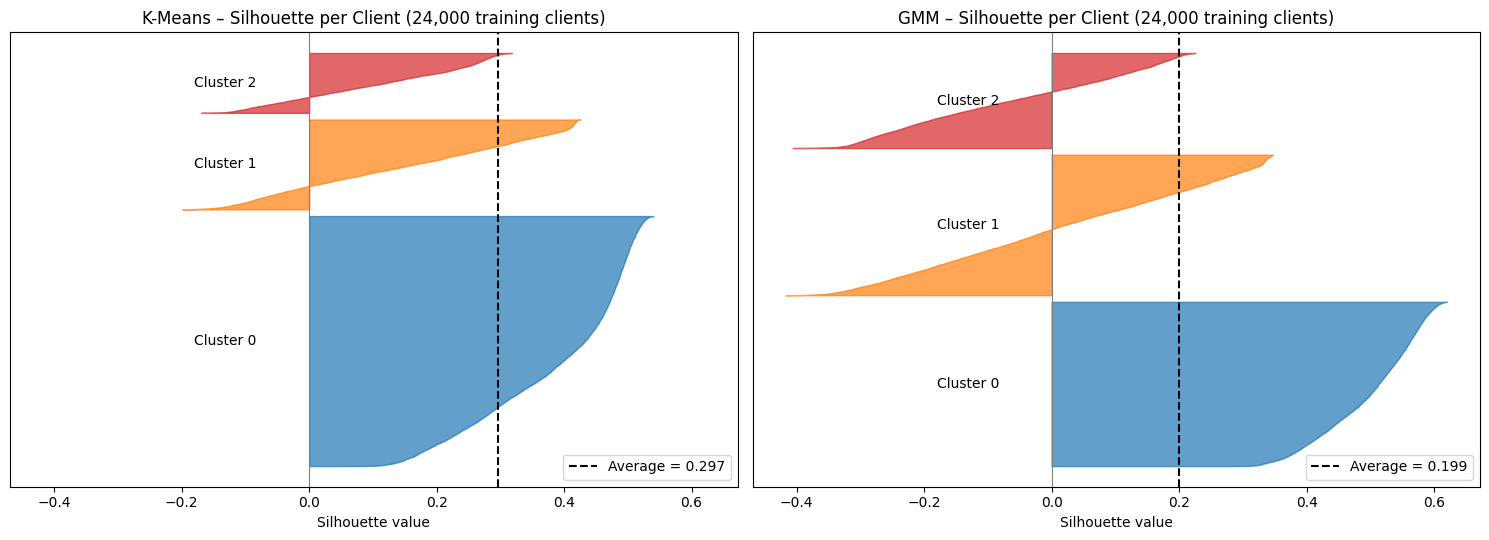

In [59]:
# silhouette value of every training client -> which clusters are well formed?
sil_values = {alg: silhouette_samples(X_train, train[col].to_numpy()) for alg, col in algorithms.items()}

per_cluster = []
for alg, col in algorithms.items():
    s = pd.Series(sil_values[alg])
    for c, g in s.groupby(train[col]):
        per_cluster.append({"Algorithm": alg, "Cluster": c, "Size": len(g),
                            "Mean silhouette": g.mean(), "% negative": (g < 0).mean() * 100})
per_cluster = pd.DataFrame(per_cluster)
display(per_cluster.round(3))

# silhouette plot
colors = ["tab:blue", "tab:orange", "tab:red"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharex=True)
for ax, (alg, col) in zip(axes, algorithms.items()):
    labels, y = train[col].to_numpy(), 0
    for c in sorted(np.unique(labels)):
        vals = np.sort(sil_values[alg][labels == c])
        ax.fill_betweenx(np.arange(y, y + len(vals)), 0, vals, color=colors[c], alpha=0.7)
        ax.text(-0.18, y + len(vals) / 2, f"Cluster {c}", va="center")
        y += len(vals) + 400
    avg = sil_values[alg].mean()
    ax.axvline(avg, color="black", linestyle="--", label=f"Average = {avg:.3f}")
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_title(f"{alg} – Silhouette per Client (24,000 training clients)")
    ax.set_xlabel("Silhouette value")
    ax.set_yticks([])
    ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_silhouette_per_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

- **K-Means:** Cluster 0 is very well formed (mean 0.39, **no** client with a negative value). Clusters 1 and 2 are weaker (0.16 and 0.11) and about 26% of their clients have a negative Silhouette, meaning they sit on the border with another cluster.
- **GMM:** Cluster 0 is even cleaner (0.50), but Cluster 1 is close to 0 (0.02) and **Cluster 2 has a negative mean (−0.06)**: 59% of its clients are closer to another cluster. GMM's high-risk group is therefore not a real compact group in distance terms.

**Takeaway:** both models find the same clean "core" group, but K-Means forms the two smaller groups much more cleanly. Border clients (negative Silhouette) should be flagged in the dashboard as "uncertain segment" (see `assignment_clarity` in "Clustering Results for System Integration").

## External Validation (BCubed and default rate)

Our dataset has a ground truth (default / no default), so we can check if the clusters are meaningful for credit risk. The label is used **only after clustering**.

- **BCubed Precision:** for each client, the share of clients in its cluster that have the same class. **BCubed Recall:** the share of clients of the same class that ended up in the same cluster.
- **Reference:** if all clients are put in one cluster, Precision = 0.655 and Recall = 1. Recall and F1 always favor fewer clusters, and our goal is **not** to rebuild a 2-class label with 3 segments. So **Precision** and the **default rate per cluster** are the useful numbers here.

In [60]:
# external validation: compare the clusters with the real default label
# (the label was never used to build the clusters, only here to judge them)

def bcubed(clusters, classes):
    """BCubed precision / recall / F1 computed from the contingency table"""
    table = pd.crosstab(clusters, classes).to_numpy().astype(float)
    n = table.sum()
    precision = (table ** 2 / table.sum(axis=1, keepdims=True)).sum() / n
    recall = (table ** 2 / table.sum(axis=0, keepdims=True)).sum() / n
    return precision, recall, 2 * precision * recall / (precision + recall)

ext = []
y_train = train[TARGET].to_numpy()
overall_rate = y_train.mean()
for alg, col in algorithms.items():
    labels = train[col].to_numpy()
    p, r, f = bcubed(labels, y_train)
    rates = pd.Series(y_train).groupby(labels).mean()
    ext.append({"Algorithm": alg, "BCubed Precision": p, "BCubed Recall": r, "BCubed F1": f,
                "ARI vs label": adjusted_rand_score(y_train, labels),
                "NMI vs label": normalized_mutual_info_score(y_train, labels),
                "Highest default rate (%)": rates.max() * 100,
                "Lowest default rate (%)": rates.min() * 100,
                "Risk lift (highest / overall)": rates.max() / overall_rate})

# reference point: putting every client in ONE cluster
p, r, f = bcubed(np.zeros(len(y_train)), y_train)
ext.append({"Algorithm": "Baseline (1 cluster)", "BCubed Precision": p, "BCubed Recall": r, "BCubed F1": f,
            "ARI vs label": 0.0, "NMI vs label": 0.0,
            "Highest default rate (%)": overall_rate * 100, "Lowest default rate (%)": overall_rate * 100,
            "Risk lift (highest / overall)": 1.0})
external = pd.DataFrame(ext).set_index("Algorithm")
print(f"Overall default rate (train): {overall_rate:.1%}")
external.round(3)

Overall default rate (train): 22.1%


,BCubed Precision,BCubed Recall,BCubed F1,ARI vs label,NMI vs label,Highest default rate (%),Lowest default rate (%),Risk lift (highest / overall)
Algorithm,,,,,,,,
K-Means,0.702,0.496,0.581,0.151,0.080,57.647,13.825,2.606
GMM,0.692,0.379,0.490,0.075,0.062,45.909,11.653,2.075
Baseline (1 cluster),0.655,1.000,0.792,0.000,0.000,22.121,22.121,1.000


**Results:**
- K-Means has higher BCubed Precision (0.702 vs 0.692), Recall (0.496 vs 0.379) and F1 (0.581 vs 0.490) than GMM. Both are above the 0.655 one-cluster precision, so the clusters contain real risk information.
- **Risk separation:** K-Means default rates range from **13.8% to 57.6%**. Its high-risk cluster is **2.6 times** the average rate (22.1%). GMM's high-risk cluster is only 2.1 times the average (45.9%) because it mixes in more good clients.
- ARI and NMI against the label are low (0.15 / 0.08 for K-Means). This is expected: clusters describe behavior, and many late payers still do not default.

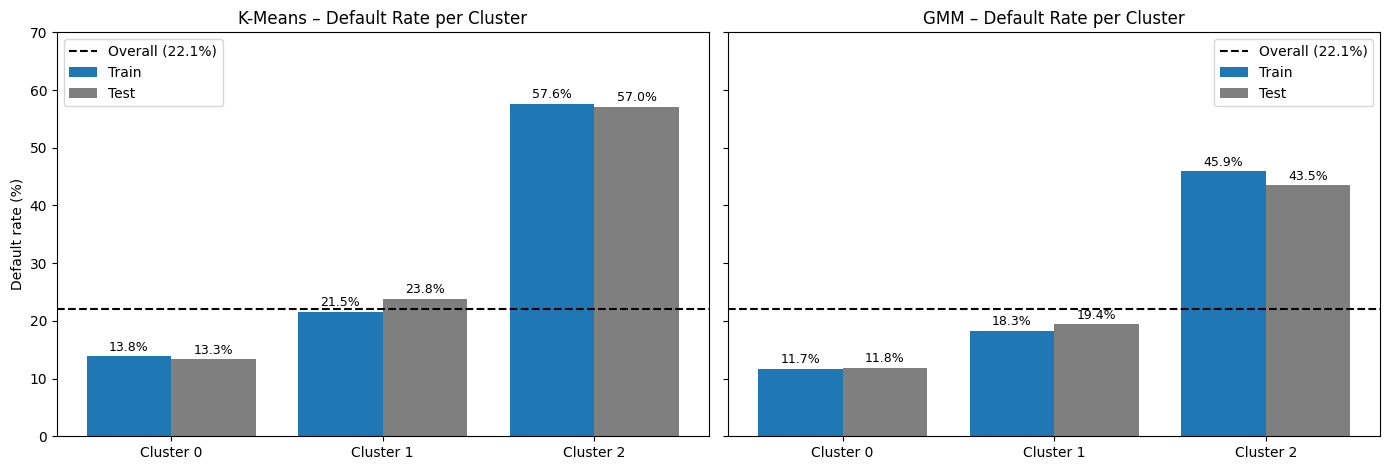

K-Means vs GMM agreement (train): ARI = 0.422, NMI = 0.522
K-Means vs GMM agreement (test): ARI = 0.413, NMI = 0.516


In [61]:
# default rate per cluster for both algorithms, train and test
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (alg, col) in zip(axes, algorithms.items()):
    rates = df.groupby([col, "split"])[TARGET].mean().unstack()[["train", "test"]] * 100
    x = np.arange(len(rates))
    ax.bar(x - 0.2, rates["train"], 0.4, label="Train", color="tab:blue")
    ax.bar(x + 0.2, rates["test"], 0.4, label="Test", color="tab:gray")
    for i in range(len(rates)):
        ax.text(i - 0.2, rates["train"].iloc[i] + 1, f"{rates['train'].iloc[i]:.1f}%", ha="center", fontsize=9)
        ax.text(i + 0.2, rates["test"].iloc[i] + 1, f"{rates['test'].iloc[i]:.1f}%", ha="center", fontsize=9)
    ax.axhline(overall_rate * 100, linestyle="--", color="black", label=f"Overall ({overall_rate:.1%})")
    ax.set_xticks(x, [f"Cluster {c}" for c in rates.index])
    ax.set_title(f"{alg} – Default Rate per Cluster")
    ax.set_ylim(0, 70)
    ax.legend()
axes[0].set_ylabel("Default rate (%)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_default_rate_per_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

# agreement between the two algorithms
for split_name, part in [("train", train), ("test", test)]:
    print(f"K-Means vs GMM agreement ({split_name}): ARI = "
          f"{adjusted_rand_score(part.kmeans_cluster, part.gmm_cluster):.3f}, "
          f"NMI = {normalized_mutual_info_score(part.kmeans_cluster, part.gmm_cluster):.3f}")

The default rates are almost identical on the train and test sets (K-Means: 13.8 → 13.3%, 21.5 → 23.8%, 57.6 → 57.0%), so the risk meaning of each segment is stable.

**Agreement between the two algorithms:** ARI = 0.42. They agree on the overall structure (as shown in the GMM section, K-Means Cluster 1 maps fully to GMM Cluster 1, and K-Means Cluster 2 almost fully to GMM Cluster 2), but GMM splits K-Means' large Cluster 0 across all 3 of its groups.

## Final Comparison: K-Means vs GMM

Algorithm,K-Means,GMM,Better
Silhouette (full train) ↑,0.2965,0.1993,K-Means
Silhouette (test) ↑,0.3019,0.1963,K-Means
Davies-Bouldin ↓,1.4071,1.6748,K-Means
Calinski-Harabasz ↑,7959.6482,6576.0259,K-Means
WCSS ↓,317424.6396,341069.7010,K-Means
BCubed F1 ↑,0.5814,0.4900,K-Means
BCubed Precision ↑,0.7019,0.6924,K-Means
Risk lift ↑,2.6060,2.0754,K-Means


K-Means wins 8 of 8 metrics


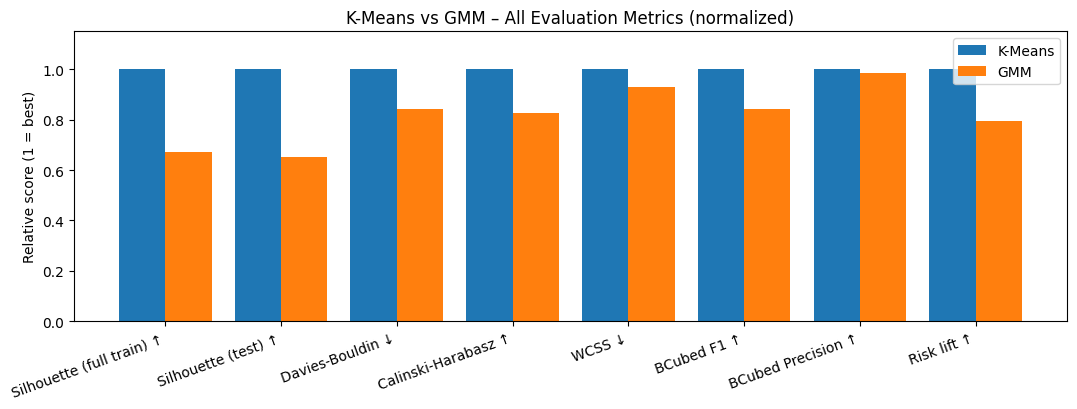

In [62]:
# one table with everything (train set) + which algorithm wins each metric
tr = internal[internal.Split == "train"].set_index("Algorithm")
summary = pd.DataFrame({
    "Silhouette (full train) ↑": tr["Silhouette"],
    "Silhouette (test) ↑": internal[internal.Split == "test"].set_index("Algorithm")["Silhouette"],
    "Davies-Bouldin ↓": tr["Davies-Bouldin"],
    "Calinski-Harabasz ↑": tr["Calinski-Harabasz"],
    "WCSS ↓": tr["WCSS"],
    "BCubed F1 ↑": external["BCubed F1"],
    "BCubed Precision ↑": external["BCubed Precision"],
    "Risk lift ↑": external["Risk lift (highest / overall)"],
}).loc[["K-Means", "GMM"]].T

summary["Better"] = [
    ("K-Means" if summary.loc[m, "K-Means"] < summary.loc[m, "GMM"] else "GMM") if "↓" in m
    else ("K-Means" if summary.loc[m, "K-Means"] > summary.loc[m, "GMM"] else "GMM")
    for m in summary.index]
summary.to_csv(RESULTS_DIR / "clustering_evaluation_summary.csv")
display(summary.round(4))
print("K-Means wins", (summary.Better == "K-Means").sum(), "of", len(summary), "metrics")

# visual comparison (normalized so that 1 = best of the two)
fig, ax = plt.subplots(figsize=(11, 4.2))
norm = summary[["K-Means", "GMM"]].copy()
for m in norm.index:
    v = norm.loc[m]
    norm.loc[m] = v.min() / v if "↓" in m else v / v.max()
x = np.arange(len(norm))
ax.bar(x - 0.2, norm["K-Means"], 0.4, label="K-Means", color="tab:blue")
ax.bar(x + 0.2, norm["GMM"], 0.4, label="GMM", color="tab:orange")
ax.set_xticks(x, norm.index, rotation=20, ha="right")
ax.set_ylabel("Relative score (1 = best)")
ax.set_ylim(0, 1.15)
ax.set_title("K-Means vs GMM – All Evaluation Metrics (normalized)")
ax.legend()
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_algorithm_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

**Selected algorithm: K-Means (k = 3).** It wins **all 8 metrics**:
- **Better-shaped clusters:** higher Silhouette and Calinski-Harabasz, lower Davies-Bouldin and WCSS, on both train and test.
- **More useful for the bank:** sharper risk separation (13.8% to 57.6% default rate) and higher BCubed scores.
- **Easier to explain and deploy:** each segment is described by one center ("the average client of the group"), and a new client is assigned by finding the nearest center. No probability model is needed.

**Why GMM did worse:** the selected GMM uses spherical covariance, so its shape assumption is close to K-Means', but it also lets the clusters overlap and have different sizes and spreads. On this data, that made the high-risk group wider and less pure. GMM is still useful as a check: its `gmm_membership` probability can show how confidently a client belongs to a segment.

The remaining sections analyze the **K-Means** clusters.

## Cluster Interpretation

### Overall feature importance
Two methods were used to find the features that define the clusters:
- **ANOVA F-value:** how different the cluster means are compared with the spread inside each cluster.
- **Surrogate decision tree:** a small tree (depth 3) trained to reproduce the K-Means labels. If it reproduces them well, the clusters can be described with a few simple rules.

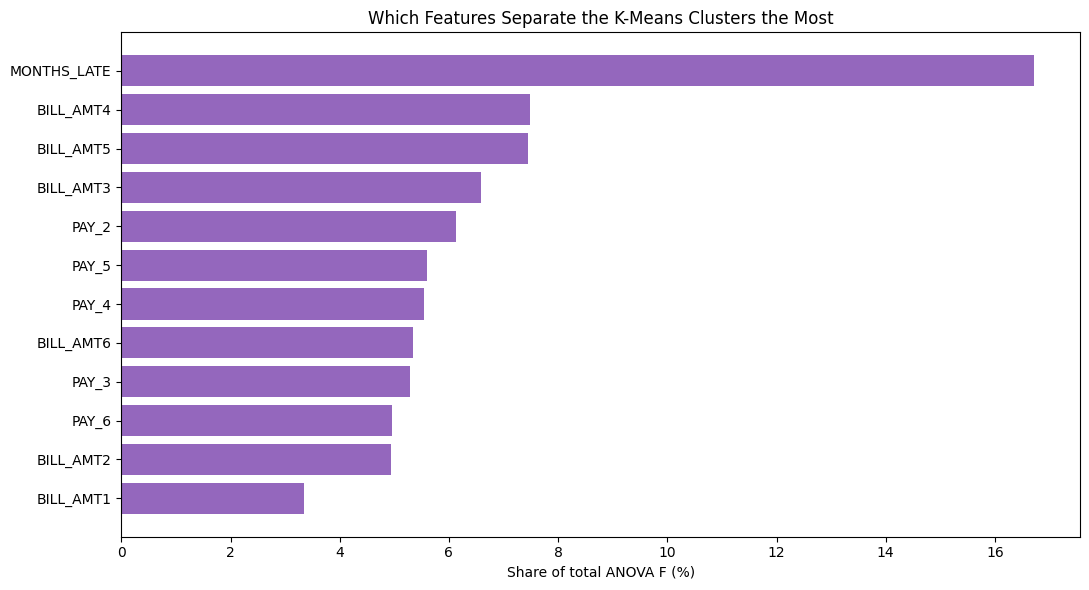

A depth-3 decision tree reproduces the K-Means clusters with 91.5% accuracy on test clients.


In [63]:
# which features separate the clusters? (overall importance)
# 1) one-way ANOVA F: how different the cluster means are compared with the spread inside clusters
from sklearn.feature_selection import f_classif
f_values, _ = f_classif(X_train, train.kmeans_cluster)

# 2) a small decision tree that tries to reproduce the K-Means labels (surrogate model)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(train[features], train.kmeans_cluster)
tree_acc_test = tree.score(test[features], test.kmeans_cluster)

importance = pd.DataFrame({"ANOVA F": f_values, "Tree importance": tree.feature_importances_},
                          index=features).sort_values("ANOVA F", ascending=False)
importance["ANOVA F (share %)"] = importance["ANOVA F"] / importance["ANOVA F"].sum() * 100

fig, ax = plt.subplots(figsize=(11, 6))
top = importance.head(12)[::-1]
ax.barh(top.index, top["ANOVA F (share %)"], color="tab:purple")
ax.set_xlabel("Share of total ANOVA F (%)")
ax.set_title("Which Features Separate the K-Means Clusters the Most")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_feature_importance_overall.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"A depth-3 decision tree reproduces the K-Means clusters with {tree_acc_test:.1%} accuracy on test clients.")

The surrogate tree reproduces the K-Means clusters with **91.5% accuracy** on test clients, so the clusters can be described with a few simple rules.

**MONTHS_LATE** is by far the most important feature (17% of the total F). It is followed by the **bill amounts (BILL_AMT3–6)** and the **repayment status codes (PAY_2–PAY_6)**. **AGE** has almost no role (all cluster centers are within ±0.1 of the average). This matches Phase 1, where the repayment status features were also the strongest predictors of default.

In [64]:
# simple rules an executive can read (from the surrogate tree, in standardized units)
print(export_text(tree, feature_names=features, decimals=2))

|--- BILL_AMT5 <= -0.34
|   |--- BILL_AMT4 <= -0.54
|   |   |--- MONTHS_LATE <= 1.72
|   |   |   |--- class: 1
|   |   |--- MONTHS_LATE >  1.72
|   |   |   |--- class: 2
|   |--- BILL_AMT4 >  -0.54
|   |   |--- BILL_AMT6 <= -0.54
|   |   |   |--- class: 1
|   |   |--- BILL_AMT6 >  -0.54
|   |   |   |--- class: 0
|--- BILL_AMT5 >  -0.34
|   |--- MONTHS_LATE <= 0.43
|   |   |--- BILL_AMT3 <= -0.91
|   |   |   |--- class: 1
|   |   |--- BILL_AMT3 >  -0.91
|   |   |   |--- class: 0
|   |--- MONTHS_LATE >  0.43
|   |   |--- MONTHS_LATE <= 1.07
|   |   |   |--- class: 2
|   |   |--- MONTHS_LATE >  1.07
|   |   |   |--- class: 2



**Reading the tree (in standardized units):**
- **Low recent bills** (BILL_AMT5 and BILL_AMT4 well below average) and few late months → **Cluster 1** (low activity).
- **Many late months** (MONTHS_LATE above about +0.4 std, i.e. at least about 2 late months) → **Cluster 2** (late payers), whatever the bill size.
- **Normal or high bills and few late months** → **Cluster 0** (active, on time).

So the segments are defined by two simple questions: *Does the client use the card?* and *Does the client pay on time?*

### Feature importance per cluster
For each cluster, the 8 features whose center is furthest from the average client (standardized units, so +1 = one standard deviation above average).

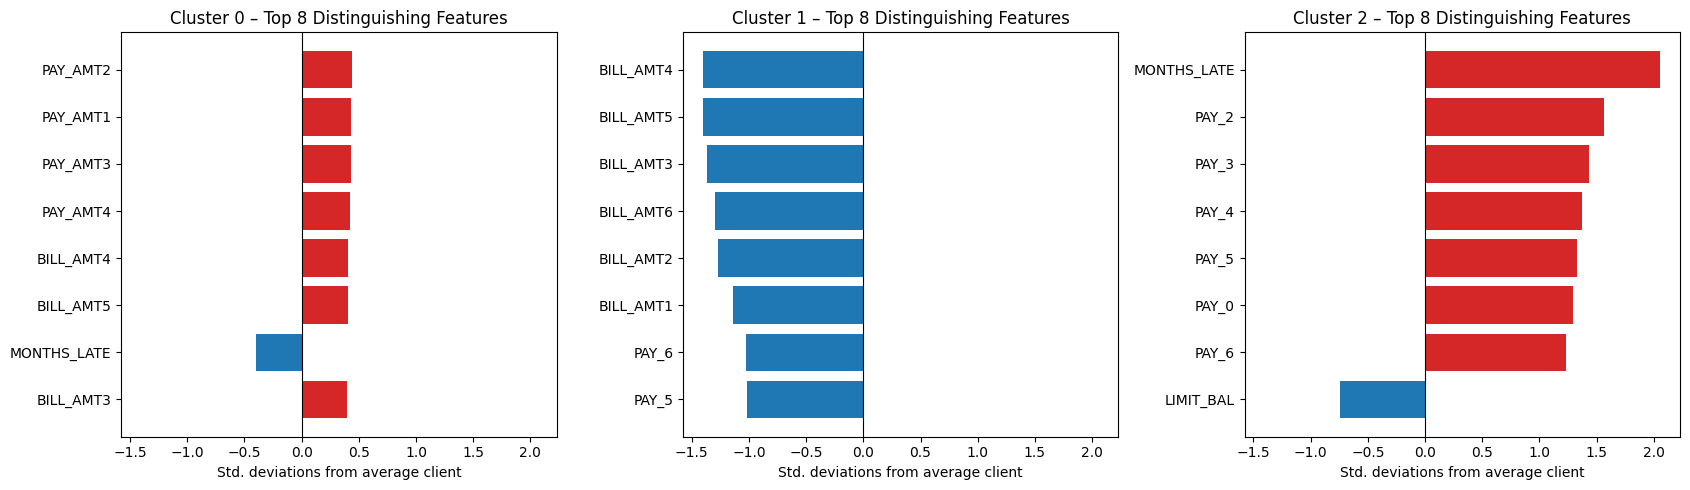

In [65]:
# feature importance PER cluster: how far each cluster center is from the average client
# (standardized units, so +1 = one standard deviation above average)
centers = train.groupby("kmeans_cluster")[features].mean()

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True)
for c, ax in zip(centers.index, axes):
    top = centers.loc[c].reindex(centers.loc[c].abs().sort_values(ascending=False).index).head(8)[::-1]
    ax.barh(top.index, top.values, color=["tab:red" if v > 0 else "tab:blue" for v in top.values])
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"Cluster {c} – Top 8 Distinguishing Features")
    ax.set_xlabel("Std. deviations from average client")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_feature_importance_per_cluster.png", dpi=150, bbox_inches="tight")
plt.show()

- **Cluster 0:** above-average payments (about +0.4) and bills (+0.3 to +0.4), and **fewer late months than average** (−0.4).
- **Cluster 1:** **very low bills** (−1.1 to −1.4), low payments (−0.8 to −1.0), low utilization (−0.8) and repayment codes far below average (PAY_2 to PAY_6 between −0.8 and −1.0, and PAY_0 −0.5, meaning "no use" or "paid in full").
- **Cluster 2:** **MONTHS_LATE +2.1** and repayment codes +1.2 to +1.6 (late payments), a lower credit limit (−0.75) and higher utilization (+0.5).

### Profiles in real units
The table uses the original data so the numbers are easy to understand (amounts in NT dollars; `payment_ratio` = total paid ÷ total billed over 6 months).

In [66]:
# cluster profiles in REAL units (raw data joined by ID)
pay_status = ["PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"]
bills = [f"BILL_AMT{i}" for i in range(1, 7)]
payments = [f"PAY_AMT{i}" for i in range(1, 7)]

r = raw.merge(df[["ID", "split", "kmeans_cluster", "gmm_cluster"]], on="ID", validate="one_to_one")
r["avg_bill"] = r[bills].mean(axis=1)
r["avg_payment"] = r[payments].mean(axis=1)
r["months_late"] = (r[pay_status] > 0).sum(axis=1)
r["utilization"] = r["BILL_AMT1"] / r["LIMIT_BAL"]
r["payment_ratio"] = (r[payments].sum(axis=1) / r[bills].clip(lower=0).sum(axis=1).replace(0, np.nan)).clip(upper=2)
r["no_activity_months"] = (r[pay_status] == -2).sum(axis=1)   # -2 = card not used that month

rt = r[r.split == "train"]
profile = rt.groupby("kmeans_cluster").agg(
    clients=("ID", "size"),
    median_credit_limit=("LIMIT_BAL", "median"),
    median_avg_bill=("avg_bill", "median"),
    median_avg_payment=("avg_payment", "median"),
    median_payment_ratio=("payment_ratio", "median"),
    median_utilization=("utilization", "median"),
    avg_months_late=("months_late", "mean"),
    pct_ever_late=("months_late", lambda s: (s > 0).mean() * 100),
    avg_no_activity_months=("no_activity_months", "mean"),
    median_age=("AGE", "median"),
    default_rate_pct=(TARGET, lambda s: s.mean() * 100),
)
profile.insert(1, "share_pct", profile["clients"] / profile["clients"].sum() * 100)
profile.T.round(2)

kmeans_cluster,0,1,2
clients,15009.00,5395.00,3596.00
share_pct,62.54,22.48,14.98
median_credit_limit,150000.00,180000.00,50000.00
median_avg_bill,33789.50,966.67,28073.00
median_avg_payment,3838.17,592.50,1483.33
median_payment_ratio,0.08,0.81,0.05
median_utilization,0.46,0.00,0.68
avg_months_late,0.22,0.43,4.03
pct_ever_late,17.80,34.03,100.00
avg_no_activity_months,0.28,2.84,0.02


The box plots below show how the key features are spread inside each cluster (outliers hidden).

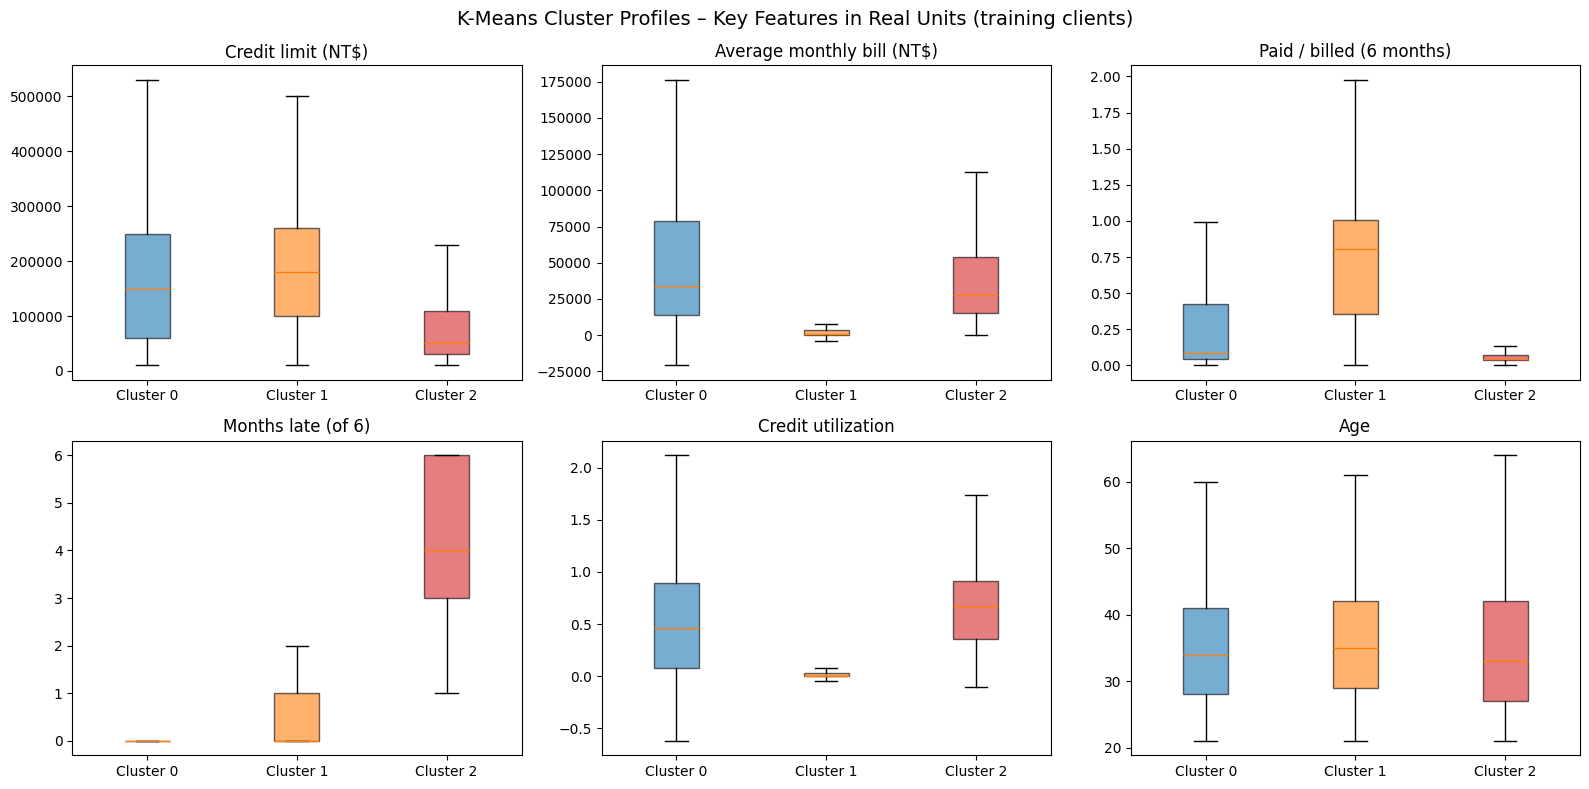

In [67]:
# distribution of key features per cluster (real units, outliers hidden)
plot_cols = [("LIMIT_BAL", "Credit limit (NT$)"), ("avg_bill", "Average monthly bill (NT$)"),
             ("payment_ratio", "Paid / billed (6 months)"), ("months_late", "Months late (of 6)"),
             ("utilization", "Credit utilization"), ("AGE", "Age")]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, title) in zip(axes.ravel(), plot_cols):
    groups = [rt.loc[rt.kmeans_cluster == c, col].dropna() for c in range(3)]
    bp = ax.boxplot(groups, tick_labels=["Cluster 0", "Cluster 1", "Cluster 2"],
                    showfliers=False, patch_artist=True)
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.6)
    ax.set_title(title)
plt.suptitle("K-Means Cluster Profiles – Key Features in Real Units (training clients)", fontsize=14)
plt.tight_layout()
plt.savefig(PLOTS_DIR / "eval_cluster_profiles_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

**What characterizes each group:**

| | Cluster 0 | Cluster 1 | Cluster 2 |
|---|---|---|---|
| Share of clients | 62.5% | 22.5% | 15.0% |
| Median credit limit | NT\$150,000 | NT\$180,000 (highest) | NT\$50,000 (lowest) |
| Median monthly bill | NT\$33,790 | NT\$967 | NT\$28,073 |
| Paid / billed (median) | 8% | 81% | 5% |
| Median utilization | 46% | 0% | 68% |
| Late months (avg of 6) | 0.2 | 0.4 | **4.0** |
| Ever late | 18% | 34% | **100%** |
| Default rate | **13.8%** | 21.5% | **57.6%** |

- **Cluster 0 – Active On-Time Payers:** they use the card a lot, with above-average bills and above-average payment amounts (as shown in the K-Means feature profile), and they almost always pay on time. Their bills are large, so the amount they pay is a small share of the bill (median 8%), but they are not late. Lowest risk.
- **Cluster 1 – Low-Activity Cardholders:** high limits but almost no use (about 2.8 of 6 months with no activity). They pay most of what they owe, yet their default rate (21.5%) is close to the average. A low bill does not automatically mean low risk.
- **Cluster 2 – Chronic Late Payers:** small limits, high utilization, every client was late at least once, with 4 late months on average, and they pay only about 5% of what they are billed. Their default rate is 2.6 times the average.

## Cluster Profiles (for the decision-support system)

In [68]:
# business profile of each cluster (used by the dashboard and the GenAI prompts)
segment_info = {
    0: {"segment_name": "Active On-Time Payers",
        "risk_level": "Low",
        "description": "Clients who use their card regularly, with above-average bills and "
                       "above-average payment amounts, and almost no late months.",
        "recommended_action": "Retain and grow: eligible for credit-limit increases, rewards and "
                              "cross-selling. Standard monitoring."},
    1: {"segment_name": "Low-Activity Cardholders",
        "risk_level": "Medium",
        "description": "Clients who barely use their card (very small bills, many months with no "
                       "activity) despite having the highest credit limits. They pay most of what "
                       "they owe, but about 1 in 3 had at least one late month.",
        "recommended_action": "Activate and verify: usage campaigns, but review any sudden jump in "
                              "spending, since the default rate is close to the portfolio average."},
    2: {"segment_name": "Chronic Late Payers",
        "risk_level": "High",
        "description": "Clients with low credit limits who use a large share of their limit and are "
                       "late on payments in most of the last 6 months; they pay only a small part "
                       "of what they are billed.",
        "recommended_action": "Act early: freeze limit increases, contact for repayment plans, "
                              "prioritize in collections and review the case manually."},
}

def key_traits(c):
    """3 short facts about the cluster from the real-unit profile"""
    p = profile.loc[c]
    return (f"median credit limit NT${p.median_credit_limit:,.0f}; "
            f"median average bill NT${p.median_avg_bill:,.0f}; "
            f"{p.avg_months_late:.1f} late months out of 6 on average")

profiles = pd.DataFrame(segment_info).T
profiles.index.name = "kmeans_cluster"
profiles["key_traits"] = [key_traits(c) for c in profiles.index]
profiles["clients_train"] = profile["clients"]
profiles["share_pct"] = profile["share_pct"].round(1)
profiles["default_rate_train_pct"] = profile["default_rate_pct"].round(1)
profiles["default_rate_test_pct"] = (test.groupby("kmeans_cluster")[TARGET].mean() * 100).round(1)
profiles["risk_vs_average"] = (profile["default_rate_pct"] / (overall_rate * 100)).round(2)
profiles["mean_silhouette"] = per_cluster.query("Algorithm == 'K-Means'").set_index("Cluster")["Mean silhouette"].round(3)
profiles[["segment_name", "risk_level", "clients_train", "share_pct", "default_rate_train_pct",
          "default_rate_test_pct", "risk_vs_average", "key_traits"]]

,segment_name,risk_level,clients_train,share_pct,default_rate_train_pct,default_rate_test_pct,risk_vs_average,key_traits
kmeans_cluster,,,,,,,,
0,Active On-Time Payers,Low,15009,62.5,13.8,13.3,0.62,"median credit limit NT$150,000; median average..."
1,Low-Activity Cardholders,Medium,5395,22.5,21.5,23.8,0.97,"median credit limit NT$180,000; median average..."
2,Chronic Late Payers,High,3596,15.0,57.6,57.0,2.61,"median credit limit NT$50,000; median average ..."


## Integration Strategy

To decide **how** the clusters should enhance the system, we checked how the Phase 1 Random Forest performs inside each segment (test set, threshold 0.5).

In [69]:
# how well does the Phase 1 model (Random Forest) work inside each segment? (test set only)
rf = pd.read_csv(ROOT / "Supervised_Learning" / "evaluation_results" / "rf_test_predictions.csv")
rf = rf.merge(test[["ID", "kmeans_cluster"]], on="ID", validate="one_to_one")
assert len(rf) == 6000

seg_perf = []
for c, g in rf.groupby("kmeans_cluster"):
    seg_perf.append({"Cluster": c, "Segment": segment_info[c]["segment_name"], "Clients": len(g),
                     "Actual default %": g.y_true.mean() * 100,
                     "Predicted default %": g.y_pred.mean() * 100,
                     "Mean RF probability": g.y_proba.mean(),
                     "Recall": recall_score(g.y_true, g.y_pred),
                     "Precision": precision_score(g.y_true, g.y_pred),
                     "ROC-AUC": roc_auc_score(g.y_true, g.y_proba),
                     "Missed defaulters": int(((g.y_true == 1) & (g.y_pred == 0)).sum())})
seg_perf = pd.DataFrame(seg_perf).set_index("Cluster")
seg_perf["% of all missed"] = seg_perf["Missed defaulters"] / seg_perf["Missed defaulters"].sum() * 100
seg_perf.to_csv(RESULTS_DIR / "rf_performance_per_segment.csv")
print("Overall RF (test): recall =", round(recall_score(rf.y_true, rf.y_pred), 3),
      "| precision =", round(precision_score(rf.y_true, rf.y_pred), 3),
      "| ROC-AUC =", round(roc_auc_score(rf.y_true, rf.y_proba), 3))
seg_perf.round(3)

Overall RF (test): recall = 0.577 | precision = 0.509 | ROC-AUC = 0.773


,Segment,Clients,Actual default %,Predicted default %,Mean RF probability,Recall,Precision,ROC-AUC,Missed defaulters,% of all missed
Cluster,,,,,,,,,,
0,Active On-Time Payers,3779,13.310,7.489,0.293,0.241,0.428,0.688,382,68.093
1,Low-Activity Cardholders,1330,23.759,26.692,0.417,0.465,0.414,0.673,169,30.125
2,Chronic Late Payers,891,57.015,97.194,0.759,0.980,0.575,0.672,10,1.783


**Findings:**
- **Cluster 2 (Chronic Late Payers):** the RF flags **97%** of these clients as defaulters. Recall is very high (98%), but precision is only 57.5%: almost half of the flagged clients do not default. The model basically treats "late payer" as "defaulter".
- **Cluster 0 (Active On-Time Payers):** recall is only **24%**. **68% of all the defaulters the RF misses are in this segment.** These are "hidden risk" clients who look good on payment history.
- ROC-AUC inside each segment is lower (0.67–0.69) than overall (0.77). Much of the RF's ranking power comes from separating the segments, and less from ranking clients within a segment.

**Integration strategy (what we propose):**
1. **Segment-aware decision thresholds:** use a lower threshold for Cluster 0 (to catch hidden defaulters) and a higher threshold or manual review for Cluster 2 (to avoid flagging every late payer). The thresholds must be tuned with cross-validation on the **training** set only, not on the test set.
2. **Dashboard:** show the client's segment next to the RF probability. A filter by segment and KPIs per segment (size, default rate, RF recall) let managers compare portfolios.
3. **Generative AI personalization:** pass the segment profile (name, risk level, key traits, recommended action) into the prompt templates, so the executive briefing explains *why* the client is risky in business terms.
4. **Cluster as an extra RF feature:** possible, but probably of limited value. The RF already uses the same PAY features that define the clusters, so this option should be tested and not assumed.

## Clustering Results for System Integration

The output files follow the repository structure given in the project handbook:

| File | Content | Used by |
|---|---|---|
| `Dataset/clustered_data.csv` | The preprocessed data of all 30,000 clients + `kmeans_cluster`, `segment_name`, `risk_level`, `gmm_cluster`, `gmm_membership` | Dashboard |
| `Unsupervised_Learning/cluster_profiles.txt` | Interpretation document: profile of each segment | Report |
| `clustering_results/cluster_profiles.json` | The same profiles in JSON (name, risk level, description, recommended action, key traits, default rates) | Generative AI prompts + dashboard |
| `clustering_results/clustering_evaluation_summary.csv` | K-Means vs GMM metrics | Report / dashboard |
| `clustering_results/rf_performance_per_segment.csv` | RF performance per segment | Dashboard KPIs |
| `clustering_results/models/segment_assigner.json` | Scaling parameters + K-Means centers to assign a **new client** | Dashboard scenario analysis |

**Why a JSON assigner instead of the joblib file:** the dashboard receives client data in **real units** (from sliders or a form), but K-Means works on standardized features. The JSON file stores the Phase 1 scaling parameters (fitted on training clients only) and the K-Means centers. The two small functions below (`preprocess_client`, `assign_segment`) can then process a raw client without scikit-learn and without depending on the scikit-learn version; the dashboard can copy them as they are. The checks below confirm that it gives the same results as the original pipeline.

**Example placeholders for the GenAI prompts:** `{segment_name}`, `{risk_level}`, `{segment_description}`, `{key_traits}`, `{segment_default_rate}`, `{recommended_action}`.

In [70]:
# 1) Dataset/clustered_data.csv: the preprocessed data + cluster labels (structure required in the handbook)
clustered = df.copy()
clustered["segment_name"] = clustered.kmeans_cluster.map(lambda c: segment_info[c]["segment_name"])
clustered["risk_level"] = clustered.kmeans_cluster.map(lambda c: segment_info[c]["risk_level"])
clustered.to_csv(ROOT / "Dataset" / "clustered_data.csv", index=False)

# 2) segment profiles as JSON (placeholders for the GenAI prompts and the dashboard)
profiles_json = {str(c): {k: (v.item() if hasattr(v, "item") else v) for k, v in row.items()}
                 for c, row in profiles.iterrows()}
(RESULTS_DIR / "cluster_profiles.json").write_text(json.dumps(profiles_json, indent=2))

# 3) Unsupervised_Learning/cluster_profiles.txt: the interpretation document
lines = ["CLUSTER PROFILES - K-Means (k = 3)",
         "Selected algorithm: K-Means (better than GMM on all evaluation metrics)",
         f"Overall default rate (train): {overall_rate:.1%}", ""]
for c, p in profiles.iterrows():
    lines += [f"Cluster {c} - {p.segment_name}",
              f"  Risk level:         {p.risk_level}",
              f"  Size (train):       {p.clients_train:,} clients ({p.share_pct}%)",
              f"  Default rate:       {p.default_rate_train_pct}% train / {p.default_rate_test_pct}% test "
              f"({p.risk_vs_average}x the average)",
              f"  Key traits:         {p.key_traits}",
              f"  Description:        {p.description}",
              f"  Recommended action: {p.recommended_action}", ""]
(UL / "cluster_profiles.txt").write_text("\n".join(lines))
print("\n".join(lines))
print("Saved: Dataset/clustered_data.csv", clustered.shape,
      "| Unsupervised_Learning/cluster_profiles.txt | clustering_results/cluster_profiles.json")

CLUSTER PROFILES - K-Means (k = 3)
Selected algorithm: K-Means (better than GMM on all evaluation metrics)
Overall default rate (train): 22.1%

Cluster 0 - Active On-Time Payers
  Risk level:         Low
  Size (train):       15,009 clients (62.5%)
  Default rate:       13.8% train / 13.3% test (0.62x the average)
  Key traits:         median credit limit NT$150,000; median average bill NT$33,790; 0.2 late months out of 6 on average
  Description:        Clients who use their card regularly, with above-average bills and above-average payment amounts, and almost no late months.
  Recommended action: Retain and grow: eligible for credit-limit increases, rewards and cross-selling. Standard monitoring.

Cluster 1 - Low-Activity Cardholders
  Risk level:         Medium
  Size (train):       5,395 clients (22.5%)
  Default rate:       21.5% train / 23.8% test (0.97x the average)
  Key traits:         median credit limit NT$180,000; median average bill NT$967; 0.4 late months out of 6 on aver

In [71]:
# 4) a small JSON "model" so the dashboard can assign a NEW client (entered in real units)
#    rebuild the Phase 1 scaling parameters from the raw TRAINING clients only
raw_train = raw[raw.ID.isin(train.ID)].copy()
raw_train["MONTHS_LATE"] = (raw_train[pay_status] > 0).sum(axis=1)
raw_train["UTILIZATION"] = raw_train["BILL_AMT1"] / raw_train["LIMIT_BAL"]

def transform_type(f):
    if f == "LIMIT_BAL" or f.startswith("PAY_AMT"):
        return "log1p"
    if f.startswith("BILL_AMT"):
        return "signed_log"
    return "none"

def apply_transform(values, kind):
    if kind == "log1p":
        return np.log1p(values)
    if kind == "signed_log":
        return np.sign(values) * np.log1p(np.abs(values))
    return values

preprocessing = {}
for f in features:
    kind = transform_type(f)
    v = apply_transform(raw_train[f].astype(float), kind)
    preprocessing[f] = {"transform": kind, "mean": float(v.mean()), "std": float(v.std(ddof=0))}

kmeans_centers = train.groupby("kmeans_cluster")[features].mean()  # = K-Means centroids
assigner = {
    "features": features,
    "preprocessing": preprocessing,
    "centers": kmeans_centers.to_numpy().tolist(),
    "profiles": {str(c): {"segment_name": segment_info[c]["segment_name"],
                          "risk_level": segment_info[c]["risk_level"],
                          "description": segment_info[c]["description"],
                          "recommended_action": segment_info[c]["recommended_action"],
                          "default_rate_train_pct": float(profiles.loc[c, "default_rate_train_pct"])}
                 for c in profiles.index},
}
(MODELS_DIR / "segment_assigner.json").write_text(json.dumps(assigner, indent=2))
print("Saved clustering_results/models/segment_assigner.json")

Saved clustering_results/models/segment_assigner.json


In [72]:
# functions the dashboard can copy to assign a new client (no scikit-learn needed)
RAW_INPUTS = ["LIMIT_BAL", "AGE"] + pay_status + bills + payments

def preprocess_client(client, assigner):
    """raw client values -> the 22 standardized K-Means features"""
    v = {c: float(client[c]) for c in RAW_INPUTS}
    v["MONTHS_LATE"] = sum(v[c] > 0 for c in pay_status)
    v["UTILIZATION"] = v["BILL_AMT1"] / v["LIMIT_BAL"]
    step = assigner["preprocessing"]
    return np.array([(apply_transform(v[f], step[f]["transform"]) - step[f]["mean"]) / step[f]["std"]
                     for f in assigner["features"]])

def assign_segment(client, assigner):
    """nearest K-Means center + segment profile + how clearly the client belongs to it"""
    dist = np.linalg.norm(np.array(assigner["centers"]) - preprocess_client(client, assigner), axis=1)
    c = int(dist.argmin())
    second = np.sort(dist)[1]
    return {"cluster": c, **assigner["profiles"][str(c)],
            "assignment_clarity": round(float(1 - dist[c] / second), 3)}

assigner_loaded = json.loads((MODELS_DIR / "segment_assigner.json").read_text())

# check 1: our rebuilt preprocessing gives exactly the Phase 1 values
sample_ids = test.ID.sample(300, random_state=RANDOM_STATE)
raw_idx = raw.set_index("ID")
rebuilt = np.array([preprocess_client(raw_idx.loc[i, RAW_INPUTS].to_dict(), assigner_loaded) for i in sample_ids])
original = df.set_index("ID").loc[sample_ids, features].to_numpy()
print("Max difference vs preprocessed_data.csv:", float(np.abs(rebuilt - original).max()))

# check 2: assigning ALL 30,000 clients reproduces the saved K-Means labels
all_clients = raw_idx.loc[df.ID, RAW_INPUTS].to_dict("records")
pred = [assign_segment(c, assigner_loaded)["cluster"] for c in all_clients]
agreement = (np.array(pred) == df.kmeans_cluster.to_numpy()).mean()
print(f"Agreement with saved K-Means labels: {agreement:.4%}")
assert agreement > 0.999

# example: how the dashboard would call it for a new client
example = raw_idx.loc[test.ID.iloc[0], RAW_INPUTS].to_dict()
assign_segment(example, assigner_loaded)

Max difference vs preprocessed_data.csv: 8.926193117986259e-13
Agreement with saved K-Means labels: 99.9967%


{'cluster': 0,
 'segment_name': 'Active On-Time Payers',
 'risk_level': 'Low',
 'description': 'Clients who use their card regularly, with above-average bills and above-average payment amounts, and almost no late months.',
 'recommended_action': 'Retain and grow: eligible for credit-limit increases, rewards and cross-selling. Standard monitoring.',
 'default_rate_train_pct': 13.8,
 'assignment_clarity': 0.158}

**Check results:** the rebuilt preprocessing matches `preprocessed_data.csv` up to rounding error (below 1e-12), and the assigner reproduces the saved K-Means labels for **99.997%** of the 30,000 clients (1 client differs, a border client whose distances to two centers are nearly equal). `assignment_clarity` shows how clearly a client belongs to its segment (0 = on the border, 1 = at the center).

## Challenges & Limitations

- **Moderate separation:** a Silhouette of about 0.3 means the segments overlap, and about 1 in 4 clients in Clusters 1 and 2 sit on a border. Segments should support a decision, not replace it.
- **Silhouette computation cost:** the full Silhouette compares every pair of clients. It was feasible for 24,000 rows (a few seconds), but for larger data a repeated-sample estimate would be needed (the repeated-sample test above shows that the sample estimate is stable).
- **BCubed with a binary label:** BCubed Recall/F1 favor a single cluster when there are only 2 classes, so they had to be interpreted with care. Precision and default rate per cluster were more informative.
- **Shape assumption:** K-Means assumes round clusters of similar spread. Monetary features are skewed, which the Phase 1 log transforms reduced but did not remove.
- **Temporal data:** the 6 monthly columns are treated as independent features, so trends (for example, a client who is getting worse) are not captured directly.
- **Fairness:** SEX and MARRIAGE were removed in Phase 1 and are not used here either. AGE is used but has almost no effect on the segments.

## Evaluation & Analysis Summary

| Item | Result |
|---|---|
| Selected algorithm | **K-Means, k = 3** (wins 8/8 metrics vs GMM) |
| Silhouette (train / test) | 0.297 / 0.302 (GMM: 0.199 / 0.196) |
| Davies-Bouldin | 1.407 (GMM: 1.675) |
| BCubed P / R / F1 | 0.702 / 0.496 / 0.581 (GMM: 0.692 / 0.379 / 0.490) |
| Segments | Active On-Time Payers (62.5%, 13.8% default) · Low-Activity Cardholders (22.5%, 21.5%) · Chronic Late Payers (15.0%, 57.6%) |
| Main drivers | MONTHS_LATE, bill amounts, repayment status codes |
| Key integration insight | 68% of the defaulters missed by the RF are in the low-risk segment → segment-aware thresholds + segment context in GenAI briefings |

In [75]:
print("Dataset:", [p.name for p in (ROOT / "Dataset").glob("clustered_data.csv")])
print("Profiles:", [p.name for p in UL.glob("cluster_profiles.txt")])
print("Results:", sorted(p.name for p in RESULTS_DIR.glob("*") if p.name.startswith(("cluster", "rf_perf"))))
print("Plots:  ", sorted(p.name for p in PLOTS_DIR.glob("eval_*")))
print("Model:  ", sorted(p.name for p in MODELS_DIR.glob("segment_*")))

Dataset: ['clustered_data.csv']
Profiles: ['cluster_profiles.txt']
Results: ['cluster_profiles.json', 'clustering_evaluation_summary.csv', 'rf_performance_per_segment.csv']
Plots:   ['eval_algorithm_comparison.png', 'eval_cluster_profiles_boxplots.png', 'eval_default_rate_per_cluster.png', 'eval_feature_importance_overall.png', 'eval_feature_importance_per_cluster.png', 'eval_silhouette_per_cluster.png']
Model:   ['segment_assigner.json']
